# Analyse Exploratoire

## Import des modules

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

## Read_csv => 2016_Building_Energy_Benchmarking

In [2]:
# building_consumption = pd.read_csv('https://s3.eu-west-1.amazonaws.com/course.oc-static.com/projects/Data_Scientist_P4/2016_Building_Energy_Benchmarking.csv')
building_consumption = pd.read_csv('2016_Building_Energy_Benchmarking.csv')

df=building_consumption.copy()  # on garde l'original et on utilise df

#### >>>Descriptions des colonnes

Ce jeu de données de la ville de Seattle (2016) recense la consommation énergétique et les émissions de gaz à effet de serre des bâtiments

Voici la description complète des colonnes du fichier, classées par thématique.  
 '-todrop-' pour les colonnes à supprimer dans le cadre du projet

***Identification et Localisation***
* **OSEBuildingID** : *Identifiant unique du bâtiment (clé primaire).* -todrop- Id  
* **DataYear** : *Année de l'étude (2016).* -todrop- 2016 only
* **BuildingType** : *Classification du type de bâtiment (ex: Non-Residential, Campus).*
* **PrimaryPropertyType** : *Usage principal du bâtiment.*
* **PropertyName** : *Nom officiel de la propriété.* -todrop- non pertinent projet
* **Address** : *Adresse physique.* -todrop- vs Neighborhood (loc)
* **City** : *Ville (Seattle).* -todrop- Seattle only
* **State** : *État (WA).*  -todrop- WA only
* **ZipCode** : *Code postal.*   -todrop- vs Neighborhood (loc)
* **TaxParcelIdentificationNumber** : *Référence cadastrale.*   -todrop- Id
* **CouncilDistrictCode** : *Numéro du district municipal.*  -todrop- vs Neighborhood (loc)
* **Neighborhood** : *Nom du quartier.*
* **Latitude** : *Coordonnée géographique nord-sud.*  -todrop- vs Neighborhood (loc)
* **Longitude** : *Coordonnée géographique est-ouest.*  -todrop- vs Neighborhood (loc)

***Caractéristiques Physiques***
* **YearBuilt** + : *Année de construction.*
* **NumberofBuildings** : *Nombre de bâtiments sur la parcelle.*
* **NumberofFloors** : *Nombre d'étages au-dessus du sol.*
* **PropertyGFATotal**  : *Surface brute totale en sq feet (sf).*
* **PropertyGFAParking** : *Surface totale dédiée au stationnement.*
* **PropertyGFABuilding(s)** : *Surface brute des bâtiments uniquement.*
* **ListOfAllPropertyUseTypes** : *Tous les usages répertoriés pour ce site.*
* **LargestPropertyUseType** : *Usage occupant la plus grande surface.*
* **LargestPropertyUseTypeGFA** : *Surface de l'usage principal.*
* **SecondLargestPropertyUseType** : *Deuxième usage en importance.*
* **SecondLargestPropertyUseTypeGFA** : *Surface du deuxième usage.*
* **ThirdLargestPropertyUseType** : *Troisième usage en importance.*
* **ThirdLargestPropertyUseTypeGFA** : *Surface du troisième usage.*

***Performance Énergétique***  
* **YearsENERGYSTARCertified** : *Années de certification Energy Star.*
* **ENERGYSTARScore**  : *Note de performance comparative Energy Star (1 à 100).*
* **SiteEUI(kBtu/sf)**  : *Consommation d'énergie du site par unité de surface.*
* **SiteEUIWN(kBtu/sf)** : *Site EUI normalisé Weather Normalized*
* **SourceEUI(kBtu/sf)**  : *Consommation totale incluant production et transport.*
* **SourceEUIWN(kBtu/sf)** : *Source EUI Weather Normalized.*
* **SiteEnergyUse(kBtu)**  : *Consommation énergétique annuelle totale.*
* **SiteEnergyUseWN(kBtu)** : *Consommation totale Weather Normalized.*

***Détails par Source d'Énergie***
* **SteamUse(kBtu)** : *Consommation de vapeur urbaine.*
* **Electricity(kWh)**  : *Consommation électrique en kilowattheures.* -todrop- vs (kBtu)
* **Electricity(kBtu)**  : *Consommation électrique convertie en kBtu.*
* **NaturalGas(therms)**  : *Consommation de gaz naturel en thermies.* -todrop- vs (kBtu)
* **NaturalGas(kBtu)**  : *Consommation de gaz naturel convertie en kBtu.*

***Qualité et Conformité***
* **DefaultData** : *Indique si des données ont été remplies par défaut.*
* **Comments** : *Commentaires additionnels sur le bâtiment.*   -todrop- vide
* **ComplianceStatus** : *État de conformité réglementaire.*
* **Outlier** : *Indique si la donnée est une valeur aberrante.*

***Émissions de Gaz à Effet de Serre***
* **TotalGHGEmissions**  : *Émissions totales de CO2 équivalent.*
* **GHGEmissionsIntensity**  : *Émissions de GES par pied carré.*


## EDA Initiale

### Aperçu - head(), info()

In [3]:
# On regarde comment un batiment est défini dans ce jeu de données 
building_consumption.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [4]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type 
building_consumption.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   object 
 3   PrimaryPropertyType              3376 non-null   object 
 4   PropertyName                     3376 non-null   object 
 5   Address                          3376 non-null   object 
 6   City                             3376 non-null   object 
 7   State                            3376 non-null   object 
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   object 
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   object 
 12  Latitude            

### Qualité et Distribution - isna(), describe(), nunique(), duplicated()

In [5]:
print("\n--- NaN ---")
print(df.isna().sum())

print("\n--- Stats numériques ---")
display(df.describe())

print("\n--- Stats catégorielles ---")
display(df.describe(include='object'))

print("\n--- Nb valeurs uniques ---")
print(df.nunique())

print("\n--- Lignes dupliquées ---", df.duplicated().sum())

# Top valeurs colonnes catégorielles
for col in df.select_dtypes(include='object').columns:
    print(f"\nTop 10 valeurs pour {col} :")
    print(df[col].value_counts().head(10))



--- NaN ---
OSEBuildingID                         0
DataYear                              0
BuildingType                          0
PrimaryPropertyType                   0
PropertyName                          0
Address                               0
City                                  0
State                                 0
ZipCode                              16
TaxParcelIdentificationNumber         0
CouncilDistrictCode                   0
Neighborhood                          0
Latitude                              0
Longitude                             0
YearBuilt                             0
NumberofBuildings                     8
NumberofFloors                        0
PropertyGFATotal                      0
PropertyGFAParking                    0
PropertyGFABuilding(s)                0
ListOfAllPropertyUseTypes             9
LargestPropertyUseType               20
LargestPropertyUseTypeGFA            20
SecondLargestPropertyUseType       1697
SecondLargestPropertyUseTyp

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,...,SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),Comments,TotalGHGEmissions,GHGEmissionsIntensity
count,3376.000000,3376.0,3360.000000,3376.000000,3376.000000,3376.000000,3376.000000,3368.000000,3376.000000,3.376000e+03,...,3.371000e+03,3.370000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,0.0,3367.000000,3367.000000
mean,21208.991114,2016.0,98116.949107,4.439277,47.624033,-122.334795,1968.573164,1.106888,4.709123,9.483354e+04,...,5.403667e+06,5.276726e+06,2.745959e+05,1.086639e+06,3.707612e+06,1.368505e+04,1.368505e+06,NaN,119.723971,1.175916
std,12223.757015,0.0,18.615205,2.120625,0.047758,0.027203,33.088156,2.108402,5.494465,2.188376e+05,...,2.161063e+07,1.593879e+07,3.912173e+06,4.352478e+06,1.485066e+07,6.709781e+04,6.709781e+06,NaN,538.832227,1.821452
min,1.000000,2016.0,98006.000000,1.000000,47.499170,-122.414250,1900.000000,0.000000,0.000000,1.128500e+04,...,0.000000e+00,0.000000e+00,0.000000e+00,-3.382680e+04,-1.154170e+05,0.000000e+00,0.000000e+00,NaN,-0.800000,-0.020000
25%,19990.750000,2016.0,98105.000000,3.000000,47.599860,-122.350662,1948.000000,1.000000,2.000000,2.848700e+04,...,9.251286e+05,9.701822e+05,0.000000e+00,1.874229e+05,6.394870e+05,0.000000e+00,0.000000e+00,NaN,9.495000,0.210000
50%,23112.000000,2016.0,98115.000000,4.000000,47.618675,-122.332495,1975.000000,1.000000,4.000000,4.417500e+04,...,1.803753e+06,1.904452e+06,0.000000e+00,3.451299e+05,1.177583e+06,3.237538e+03,3.237540e+05,NaN,33.920000,0.610000
75%,25994.250000,2016.0,98122.000000,7.000000,47.657115,-122.319407,1997.000000,1.000000,5.000000,9.099200e+04,...,4.222455e+06,4.381429e+06,0.000000e+00,8.293178e+05,2.829632e+06,1.189033e+04,1.189034e+06,NaN,93.940000,1.370000
max,50226.000000,2016.0,98272.000000,7.000000,47.733870,-122.220966,2015.000000,111.000000,99.000000,9.320156e+06,...,8.739237e+08,4.716139e+08,1.349435e+08,1.925775e+08,6.570744e+08,2.979090e+06,2.979090e+08,NaN,16870.980000,34.090000



--- Stats catégorielles ---


,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,TaxParcelIdentificationNumber,Neighborhood,ListOfAllPropertyUseTypes,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType,YearsENERGYSTARCertified,ComplianceStatus,Outlier
count,3376,3376,3376,3376,3376,3376,3376,3376,3367,3356,1679,596,119,3376,32
unique,8,24,3362,3354,1,1,3268,19,466,56,50,44,65,4,2
top,NonResidential,Low-Rise Multifamily,Northgate Plaza,2600 SW Barton St,Seattle,WA,1625049001,DOWNTOWN,Multifamily Housing,Multifamily Housing,Parking,Retail Store,2016,Compliant,Low outlier
freq,1460,987,3,4,3376,3376,8,573,866,1667,976,110,14,3211,23



--- Nb valeurs uniques ---
OSEBuildingID                      3376
DataYear                              1
BuildingType                          8
PrimaryPropertyType                  24
PropertyName                       3362
Address                            3354
City                                  1
State                                 1
ZipCode                              55
TaxParcelIdentificationNumber      3268
CouncilDistrictCode                   7
Neighborhood                         19
Latitude                           2876
Longitude                          2656
YearBuilt                           113
NumberofBuildings                    17
NumberofFloors                       50
PropertyGFATotal                   3195
PropertyGFAParking                  496
PropertyGFABuilding(s)             3193
ListOfAllPropertyUseTypes           466
LargestPropertyUseType               56
LargestPropertyUseTypeGFA          3122
SecondLargestPropertyUseType         50
SecondLarges

## Nettoyage Technique

### Suppression des colonnes non pertinentes ou redondantes

In [6]:
cols2drop=[        # Les colonnes à droper
    'OSEBuildingID',                 # non pertinent projet
    'DataYear',                      # valeur unique = 2016
    'PropertyName',                  # non pertinent projet
    'Address',                       # preference Neighborhood (loc)
    'City',                          # valeur unique = 'Seattle'
    'State',                         # valeur unique = 'WA'
    'ZipCode',                       # preference Neighborhood (loc)
    'TaxParcelIdentificationNumber', # Id non pertinent projet
    'CouncilDistrictCode',           # preference Neighborhood (loc)
    'Latitude',                      # preference Neighborhood (loc)
    'Longitude',                     # preference Neighborhood (loc)
    'Comments',                      # vide
    'Electricity(kWh)',              # preference equivalent unité kBtu   
    'NaturalGas(therms)',            # preference equivalent unité kBtu
    'SourceEUI(kBtu/sf)',            # ne correspond pas a la cible demandée (=solo la conso du batiment)
    'SourceEUIWN(kBtu/sf)',          # ne correspond pas a la cible demandée
    'YearsENERGYSTARCertified'       # presque vide
]

display('Shape Avant:',df.shape)
df.drop(columns=cols2drop, inplace=True) #, errors='ignore')     # on drop
display('Shape Après:',df.shape)

'Shape Avant:'

(3376, 46)

'Shape Après:'

(3376, 29)

### Filtrage pour ne garder que les batiments "Nonresidential*' et 'Compliant' => df_model

In [7]:
# 1. Filtrer sur le Non-Résidentiel uniquement
display('Shape Avant:',df.shape)
df_model = df[df['BuildingType'].isin(['NonResidential', 'Nonresidential COS', 'Nonresidential WA'])].copy()
display('Shape Apres 1 (df_model):',df_model.shape)
# 2. Garder uniquement les bâtiments conformes (Compliant)
df_model = df_model[df_model['ComplianceStatus'] == 'Compliant']
display('Shape Apres 2 (df_model):',df_model.shape)

'Shape Avant:'

(3376, 29)

'Shape Apres 1 (df_model):'

(1546, 29)

'Shape Apres 2 (df_model):'

(1514, 29)

In [8]:
display('Shape Avant:',df_model.shape)
df_model.drop(columns=['BuildingType','ComplianceStatus'], inplace=True) #, errors='ignore')     # on drop
display('Shape Après:',df_model.shape)

'Shape Avant:'

(1514, 29)

'Shape Après:'

(1514, 27)

### Analyse post 1er nettoyage (df_model)

In [9]:
df_model.describe()

,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
count,1514.000000,1514.000000,1514.000000,1.514000e+03,1514.000000,1.514000e+03,1.510000e+03,829.000000,340.000000,984.000000,1514.000000,1513.000000,1.514000e+03,1.513000e+03,1.514000e+03,1.514000e+03,1.514000e+03,1514.000000,1514.000000
mean,1961.542272,1.034346,4.320343,1.122383e+05,14058.414135,9.817993e+04,9.076998e+04,35251.687934,13417.095290,63.427846,74.833620,77.292531,7.726794e+06,7.835888e+06,5.044881e+05,5.476749e+06,1.700002e+06,167.408151,1.631764
std,32.817364,0.565717,6.845072,1.903593e+05,44089.922710,1.664155e+05,1.554700e+05,62785.801934,28116.155563,28.811607,75.468197,76.459428,1.879214e+07,1.895579e+07,5.358022e+06,1.310860e+07,5.554680e+06,575.982871,2.259093
min,1900.000000,0.000000,0.000000,1.128500e+04,0.000000,3.636000e+03,5.656000e+03,0.000000,0.000000,1.000000,1.400000,0.000000,5.713320e+04,0.000000e+00,0.000000e+00,-1.154170e+05,0.000000e+00,-0.800000,-0.020000
25%,1930.000000,1.000000,1.000000,2.880000e+04,0.000000,2.780000e+04,2.498850e+04,5561.000000,2587.750000,43.000000,34.700001,36.900002,1.233141e+06,1.297917e+06,0.000000e+00,7.254918e+05,0.000000e+00,20.092500,0.350000
50%,1965.000000,1.000000,2.000000,4.769250e+04,0.000000,4.563700e+04,4.154300e+04,12023.000000,5806.000000,70.000000,53.599998,56.200001,2.665809e+06,2.786649e+06,0.000000e+00,1.699671e+06,4.596750e+05,49.215000,0.875000
75%,1988.000000,1.000000,4.000000,1.034245e+05,0.000000,9.359625e+04,8.934400e+04,31033.000000,12351.500000,88.000000,84.674997,87.699997,7.064835e+06,7.335906e+06,0.000000e+00,5.126331e+06,1.446404e+06,140.830000,1.950000
max,2015.000000,9.000000,99.000000,1.952220e+06,512608.000000,1.765970e+06,1.680937e+06,441551.000000,303910.000000,100.000000,834.400024,834.400024,2.930908e+08,2.966717e+08,1.349435e+08,2.745325e+08,1.381912e+08,12307.160000,25.710000


==> à Checker YearBuilt=1900, NumebrofBuildings=0, NumberofFloors=99, SiteEUIWN/SourceEUI/WN <=0

In [10]:
df_model.describe(include=['object', 'bool'])

,PrimaryPropertyType,Neighborhood,ListOfAllPropertyUseTypes,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType,DefaultData,Outlier
count,1514,1514,1514,1510,829,340,1514,0
unique,21,19,361,55,47,38,1,0
top,Small- and Mid-Sized Office,DOWNTOWN,Office,Office,Parking,Office,False,NaN
freq,286,345,132,483,326,48,1514,NaN


==> à supprimer: colonne Outlier (vide) et colonne DefaultData (valeur unique False)

In [11]:
df_model[df_model['NumberofBuildings'] == 0][[ 'PrimaryPropertyType', 'PropertyGFATotal','NumberofBuildings','NumberofFloors']]

,PrimaryPropertyType,PropertyGFATotal,NumberofBuildings,NumberofFloors
63,Medical Office,179014,0.0,3
76,Small- and Mid-Sized Office,66240,0.0,2
160,Warehouse,79600,0.0,4
201,Large Office,100734,0.0,3
241,Small- and Mid-Sized Office,99005,0.0,5
264,Mixed Use Property,88400,0.0,1
278,Large Office,132326,0.0,10
280,Hotel,332067,0.0,19
291,Other,267335,0.0,4
358,Other,113780,0.0,1


### YearBuild == 1900 => valeur par défaut => suppression de 41 lignes

In [12]:
df_model['YearBuilt'].value_counts().sort_values(ascending=False)

YearBuilt
1900    41
1970    29
2000    29
1910    28
1960    28
        ..
1944     2
1903     1
1936     1
1935     1
1939     1
Name: count, Length: 113, dtype: int64

41 batiments pour l'année 1900 = incohérent au vu des autres années de construction => valeur par défaut (cf non renseigné)

In [13]:
display('Shape avant:',df_model.shape)
df_model = df_model[df_model['YearBuilt'] > 1900].copy()
display('Shape après:',df_model.shape)

'Shape avant:'

(1514, 27)

'Shape après:'

(1473, 27)

### Suppression du batiment à 99 etage = erreur / Seattle Chinese Baptist Church (1 ligne)

In [14]:
df_model[df_model['NumberofFloors'] == 99]

,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,...,SiteEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
1359,Worship Facility,GREATER DUWAMISH,1977,1.0,99,21948,0,21948,Worship Facility,Worship Facility,...,14.9,326001.1875,326001.1875,0.0,326001.0,0.0,False,NaN,2.27,0.1


In [15]:
building_consumption.loc[1359]

OSEBuildingID                                               21611
DataYear                                                     2016
BuildingType                                       NonResidential
PrimaryPropertyType                              Worship Facility
PropertyName                       Seattle Chinese Baptist Church
Address                                  5801 Beacon Avenue South
City                                                      Seattle
State                                                          WA
ZipCode                                                   98108.0
TaxParcelIdentificationNumber                          2124049098
CouncilDistrictCode                                             2
Neighborhood                                     GREATER DUWAMISH
Latitude                                                 47.55072
Longitude                                              -122.30265
YearBuilt                                                    1977
NumberofBu

In [16]:
display('Shape avant:',df_model.shape)
df_model = df_model[df_model['NumberofFloors'] != 99].copy()
display('Shape après:',df_model.shape)

'Shape avant:'

(1473, 27)

'Shape après:'

(1472, 27)

### NumberofBuildings == 0  Correction à 1 (52 lignes)

In [17]:
df_model[df_model['NumberofBuildings']==0]

,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,...,SiteEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
63,Medical Office,EAST,1965,0.0,3,179014,0,179014,Medical Office,Medical Office,...,92.300003,1.670106e+07,1.652771e+07,0.000000e+00,9886484.0,6814570.0,False,NaN,430.84,2.41
76,Small- and Mid-Sized Office,MAGNOLIA / QUEEN ANNE,1986,0.0,2,66240,2352,63888,"Data Center, Distribution Center, Office, Park...",Office,...,75.400002,4.166306e+06,4.192108e+06,0.000000e+00,4166305.0,0.0,False,NaN,29.04,0.44
160,Warehouse,GREATER DUWAMISH,1916,0.0,4,79600,0,79600,Non-Refrigerated Warehouse,Non-Refrigerated Warehouse,...,30.299999,2.411402e+06,2.411402e+06,0.000000e+00,2411402.0,0.0,False,NaN,16.81,0.21
201,Large Office,DOWNTOWN,1968,0.0,3,100734,26731,74003,Office,Office,...,98.199997,9.788717e+06,9.892566e+06,0.000000e+00,9788716.0,0.0,False,NaN,68.24,0.68
241,Small- and Mid-Sized Office,NORTHEAST,1961,0.0,5,99005,0,99005,Office,Office,...,63.000000,4.728488e+06,5.008124e+06,0.000000e+00,2863212.0,1865277.0,False,NaN,119.03,1.20
264,Mixed Use Property,GREATER DUWAMISH,1970,0.0,1,88400,0,88400,"Distribution Center, Non-Refrigerated Warehous...",Non-Refrigerated Warehouse,...,53.000000,4.383100e+06,4.811200e+06,0.000000e+00,2530658.0,1852442.0,False,NaN,116.03,1.31
278,Large Office,DOWNTOWN,1926,0.0,10,132326,0,132326,"Office, Other, Retail Store",Office,...,53.700001,6.029020e+06,6.146692e+06,3.282471e+05,5698221.0,2551.0,False,NaN,65.20,0.49
280,Hotel,DOWNTOWN,1973,0.0,19,332067,59280,272787,Hotel,Hotel,...,114.400002,3.778555e+07,3.798415e+07,1.558601e+07,19800542.0,2398995.0,False,NaN,1468.50,4.42
291,Other,DOWNTOWN,1996,0.0,4,267335,166960,100375,"Movie Theater, Other - Restaurant/Bar, Parking",Parking,...,75.800003,7.273156e+06,7.378420e+06,0.000000e+00,5169902.0,2103253.0,False,NaN,147.75,0.55
358,Other,DELRIDGE,1955,0.0,1,113780,0,113780,"Office, Other - Services",Other - Services,...,35.299999,3.574542e+06,4.021869e+06,0.000000e+00,1470885.0,2103657.0,False,NaN,121.98,1.07


In [18]:
df_model['NumberofBuildings'] = df_model['NumberofBuildings'].replace(0, 1)   # 0 building error => correction = 1

### Suppression des colonnes Outlier (vide) et DefaultData (valeur unique)

In [19]:
display('Shape Avant:',df_model.shape)
df_model.drop(columns=['Outlier','DefaultData'], inplace=True) #, errors='ignore')     # colonne Outlier maintenant copmpletement vide
display('Shape Après:',df_model.shape)

'Shape Avant:'

(1472, 27)

'Shape Après:'

(1472, 25)

### SiteEUIWN et SiteEnergyUseWN: remplacement des 0 ou Nan par les valeurs de SiteEUI et SiteEnergyUse

In [20]:
df_model[df_model['SiteEUIWN(kBtu/sf)'].isna()]

,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,...,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
563,Large Office,DOWNTOWN,1979,1.0,7,131143,87160,43983,"Office, Retail Store",Office,...,93.0,39.5,NaN,5177270.5,NaN,0.0,4871126.0,1416041.0,109.16,0.83


In [21]:
df_model[df_model['SiteEUIWN(kBtu/sf)']==0]

,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,...,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
220,Large Office,DOWNTOWN,1958,1.0,17,378525,84600,293925,"Office, Parking",Office,...,69.0,105.199997,0.0,2.490613e+07,0.0,10921066.00,13985064.0,0.0,940.47,2.48
247,Large Office,DOWNTOWN,1988,1.0,20,497513,118744,378769,"Office, Parking",Office,...,65.0,73.000000,0.0,2.682322e+07,0.0,0.00,26602310.0,220905.0,197.19,0.40
284,Large Office,DOWNTOWN,1929,1.0,15,151039,0,151039,Office,Office,...,84.0,43.400002,0.0,5.446624e+06,0.0,2850077.75,2596546.0,0.0,238.09,1.58
350,Small- and Mid-Sized Office,MAGNOLIA / QUEEN ANNE,1971,1.0,5,88000,21600,66400,"Office, Parking",Office,...,75.0,50.000000,0.0,3.484916e+06,0.0,0.00,3484915.0,0.0,24.29,0.28
882,Worship Facility,Northwest,1910,1.0,2,23931,0,23931,Worship Facility,Worship Facility,...,88.0,20.700001,0.0,4.964773e+05,0.0,0.00,167075.0,329402.0,18.66,0.78
953,Worship Facility,NORTHEAST,2000,1.0,2,31386,0,31386,Worship Facility,Worship Facility,...,52.0,37.599998,0.0,1.128179e+06,0.0,0.00,710478.0,417701.0,27.14,0.86
3275,University,NORTHEAST,1969,1.0,4,58779,0,58779,College/University,College/University,...,NaN,85.099998,0.0,5.000717e+06,0.0,0.00,3719217.0,0.0,25.93,0.44
3277,University,NORTHEAST,1998,1.0,6,203030,0,203030,College/University,College/University,...,NaN,252.000000,0.0,5.116831e+07,0.0,0.00,28614613.0,0.0,199.48,0.98


In [22]:
df_model.loc[df_model['SiteEUIWN(kBtu/sf)'] == 0, 'SiteEUIWN(kBtu/sf)'] = df_model['SiteEUI(kBtu/sf)']

In [23]:
df_model.loc[df_model['SiteEUIWN(kBtu/sf)'].isna(),'SiteEUIWN(kBtu/sf)'] = df_model['SiteEUI(kBtu/sf)']

In [24]:
df_model.loc[df_model['SiteEnergyUseWN(kBtu)']==0,'SiteEnergyUseWN(kBtu)'] = df_model['SiteEnergyUse(kBtu)']

In [25]:
df_model.loc[df_model['SiteEnergyUseWN(kBtu)'].isna(),'SiteEnergyUseWN(kBtu)'] = df_model['SiteEnergyUse(kBtu)']

### Check NaN restants (df_model)

In [26]:
print(df_model.isna().sum())

PrimaryPropertyType                   0
Neighborhood                          0
YearBuilt                             0
NumberofBuildings                     0
NumberofFloors                        0
PropertyGFATotal                      0
PropertyGFAParking                    0
PropertyGFABuilding(s)                0
ListOfAllPropertyUseTypes             0
LargestPropertyUseType                4
LargestPropertyUseTypeGFA             4
SecondLargestPropertyUseType        672
SecondLargestPropertyUseTypeGFA     672
ThirdLargestPropertyUseType        1143
ThirdLargestPropertyUseTypeGFA     1143
ENERGYSTARScore                     511
SiteEUI(kBtu/sf)                      0
SiteEUIWN(kBtu/sf)                    0
SiteEnergyUse(kBtu)                   0
SiteEnergyUseWN(kBtu)                 0
SteamUse(kBtu)                        0
Electricity(kBtu)                     0
NaturalGas(kBtu)                      0
TotalGHGEmissions                     0
GHGEmissionsIntensity                 0


### Remplacement de LargestPropertyUseType et LargestPropertyUseTypeGFA ==Nan  (4 lignes)

In [27]:
df_model[df_model['LargestPropertyUseType'].isna()][[ 'PrimaryPropertyType','LargestPropertyUseType','SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType', 'ListOfAllPropertyUseTypes']]

,PrimaryPropertyType,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType,ListOfAllPropertyUseTypes
353,Self-Storage Facility,NaN,NaN,NaN,"Fitness Center/Health Club/Gym, Office, Other ..."
1147,Hotel,NaN,NaN,NaN,Hotel
2414,Small- and Mid-Sized Office,NaN,NaN,NaN,Office
2459,Restaurant,NaN,NaN,NaN,Restaurant


In [28]:
df_model.loc[df_model['LargestPropertyUseType'].isna(),'LargestPropertyUseType'] = (
            df_model['ListOfAllPropertyUseTypes'].str.split(',').str[0].str.strip())

In [29]:
df_model[df_model['LargestPropertyUseTypeGFA'].isna()]

,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,...,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
353,Self-Storage Facility,BALLARD,1946,2.0,2,111445,0,111445,"Fitness Center/Health Club/Gym, Office, Other ...",Fitness Center/Health Club/Gym,...,NaN,47.799999,51.000000,5.697472e+06,6.076957e+06,0.0,3007514.0,2689958.0,163.83,1.47
1147,Hotel,DOWNTOWN,1910,1.0,8,61721,0,61721,Hotel,Hotel,...,93.0,52.200001,53.500000,2.897080e+06,2.968430e+06,0.0,2534592.0,362488.0,36.92,0.60
2414,Small- and Mid-Sized Office,LAKE UNION,2008,1.0,4,48350,0,48350,Office,Office,...,45.0,72.199997,74.699997,3.168131e+06,3.280956e+06,0.0,3168131.0,0.0,22.09,0.46
2459,Restaurant,DOWNTOWN,1913,1.0,3,28800,0,28800,Restaurant,Restaurant,...,NaN,31.200001,32.500000,8.999242e+05,9.358332e+05,0.0,402907.0,497017.0,29.21,1.01


In [30]:
df_model.loc[df_model['LargestPropertyUseTypeGFA'].isna(),'LargestPropertyUseTypeGFA'] = df_model['PropertyGFATotal']

### ENERGYSTARScore = Nan => 0 pour non référencé

In [31]:
df_model['ENERGYSTARScore'] = df_model['ENERGYSTARScore'].fillna(0)

### Suppression de 2 lignes avec Conso Elec negative (batiment special BullitCenter avec panneaux solaires) ou nulle (SuperMarché = Erreur)

In [32]:
df_model[df_model['Electricity(kBtu)']<=0]

,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,...,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
513,Supermarket / Grocery Store,MAGNOLIA / QUEEN ANNE,2008,1.0,1,57176,0,57176,"Personal Services (Health/Beauty, Dry Cleaning...",Supermarket/Grocery Store,...,31.0,208.800003,214.100006,1.252517e+07,1.284386e+07,0.0,0.0,0.0,0.0,0.00
3206,Small- and Mid-Sized Office,CENTRAL,2013,1.0,6,52000,0,52000,Office,Office,...,100.0,7.100000,5.000000,3.427261e+05,2.401321e+05,0.0,-115417.0,0.0,-0.8,-0.02


In [33]:
df_model=df_model[df_model['Electricity(kBtu)']>0].copy()

# *TERMINER L'ANALYSE EXPLORATOIRE (Indications Template)*

A réaliser : 
- Une analyse descriptive des données, y compris une explication du sens des colonnes gardées, des arguments derrière la suppression de lignes ou de colonnes, des statistiques descriptives et des visualisations pertinentes.

Qelques pistes d'analyse : 

* Identifier les colonnes avec une majorité de valeurs manquantes ou constantes en utilisant la méthode value_counts() de Pandas
* Mettre en evidence les différences entre les immeubles mono et multi-usages
* Utiliser des pairplots et des boxplots pour faire ressortir les outliers ou des batiments avec des valeurs peu cohérentes d'un point de vue métier 

Pour vous inspirer, ou comprendre l'esprit recherché dans une analyse exploratoire, vous pouvez consulter ce notebook en ligne : https://www.kaggle.com/code/pmarcelino/comprehensive-data-exploration-with-python. Il ne s'agit pas d'un modèle à suivre à la lettre ni d'un template d'analyses attendues pour ce projet. 

# Quelques Graphiques - Analyse visuelle

## Pairplot

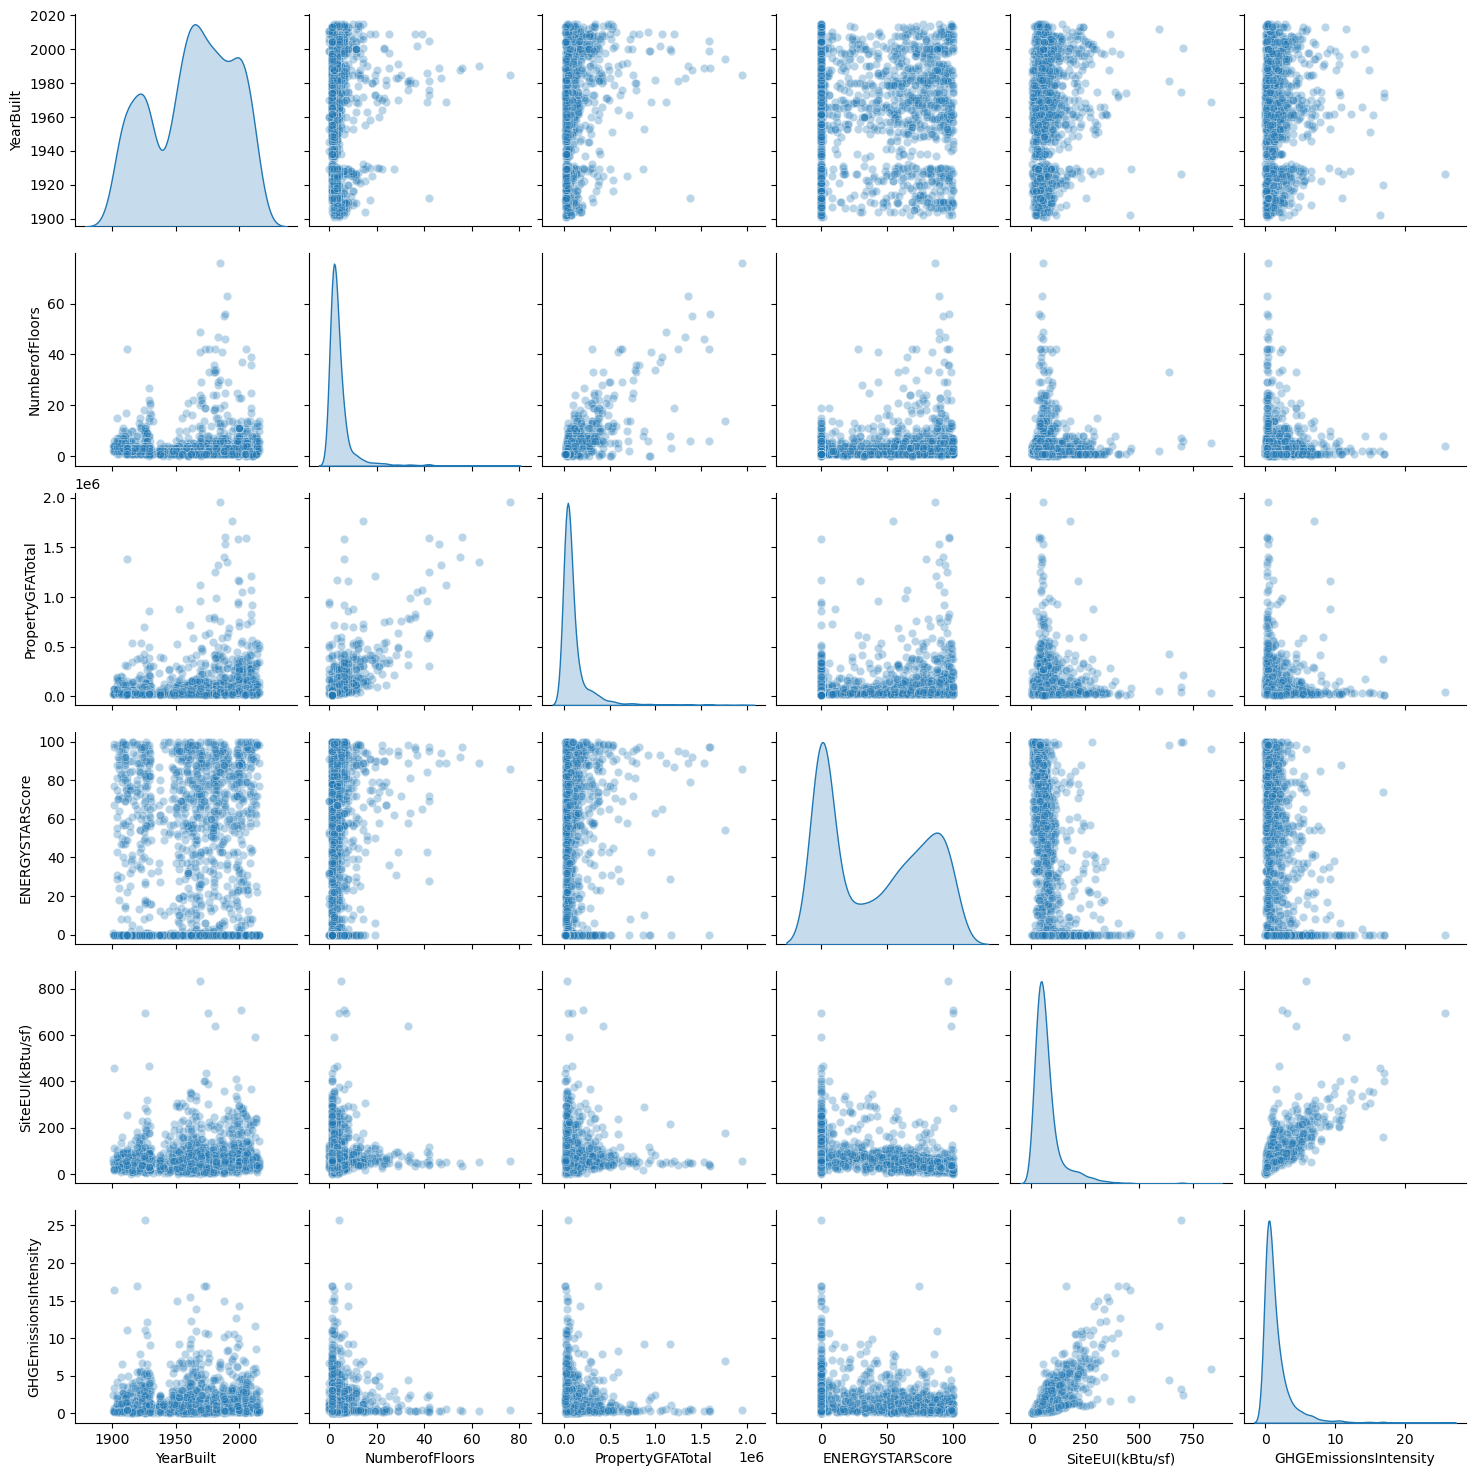

In [34]:
cols_pairplot = ['YearBuilt', 'NumberofFloors', 'PropertyGFATotal', 
                 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)', 'GHGEmissionsIntensity']

sns.pairplot(df_model[cols_pairplot], diag_kind='kde', plot_kws={'alpha': 0.3})
plt.show()

## Boxplot => drop de la ligne ou PrimaryPropertyType == 'Low-Rise Multifamily (=residentiel=hors scope)

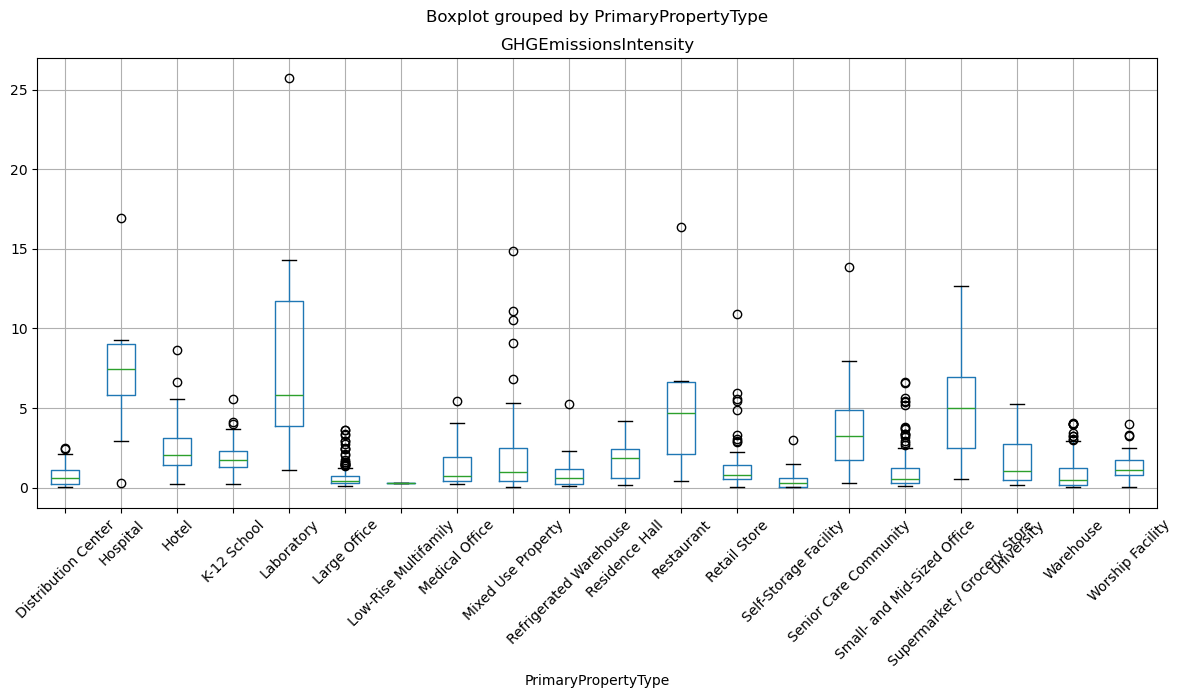

In [35]:
df_plot = df_model[df_model['PrimaryPropertyType'] != 'Other'].copy()
df_plot.boxplot(column='GHGEmissionsIntensity', by='PrimaryPropertyType', rot=45, figsize=(14,6))
plt.show()

In [36]:
df_model['PrimaryPropertyType'].value_counts()

PrimaryPropertyType
Small- and Mid-Sized Office    263
Other                          232
Warehouse                      182
Large Office                   165
Mixed Use Property             105
Retail Store                    83
Hotel                           75
Worship Facility                66
Distribution Center             53
Supermarket / Grocery Store     39
Medical Office                  39
K-12 School                     38
Self-Storage Facility           28
Residence Hall                  21
Senior Care Community           20
University                      18
Refrigerated Warehouse          12
Hospital                        10
Laboratory                      10
Restaurant                      10
Low-Rise Multifamily             1
Name: count, dtype: int64

In [37]:
df_model[df_model['PrimaryPropertyType'] == 'Low-Rise Multifamily']

,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,...,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
644,Low-Rise Multifamily,LAKE UNION,2000,1.0,3,93079,36093,56986,Multifamily Housing,Multifamily Housing,...,32.0,21.9,23.0,1997181.5,2090011.625,0.0,1744199.0,252982.0,25.6,0.28


In [38]:
display('Shape Avant:',df_model.shape)
df_model = df_model[df_model['PrimaryPropertyType'] != 'Low-Rise Multifamily'].copy()
display('Shape Après:',df_model.shape)

'Shape Avant:'

(1470, 25)

'Shape Après:'

(1469, 25)

## Histplot

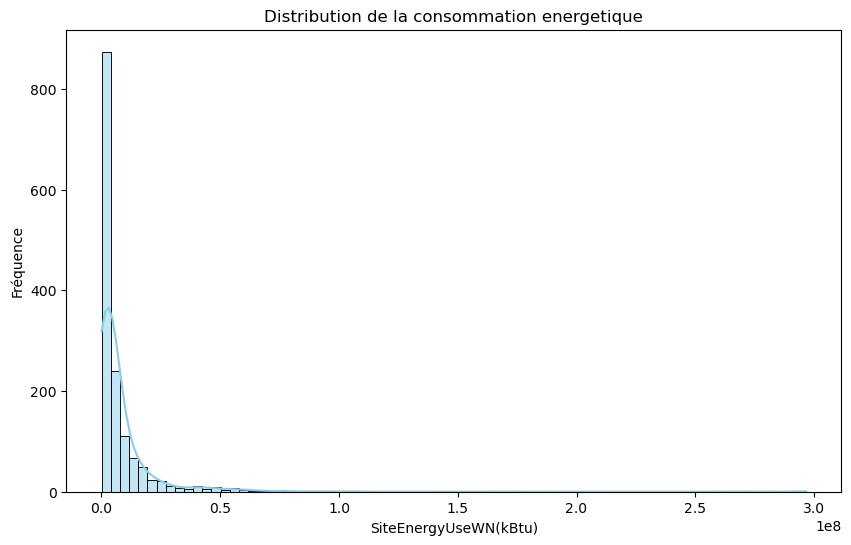

In [39]:
plt.figure(figsize=(10, 6))
sns.histplot(df_model['SiteEnergyUseWN(kBtu)'], kde=True, color='skyblue')

plt.title('Distribution de la consommation energetique')
plt.xlabel('SiteEnergyUseWN(kBtu)')
plt.ylabel('Fréquence')
plt.show()

In [40]:
df_model.sort_values(by='GHGEmissionsIntensity', ascending=False)[['PrimaryPropertyType', 'YearBuilt', 'GHGEmissionsIntensity']]

,PrimaryPropertyType,YearBuilt,GHGEmissionsIntensity
809,Laboratory,1926,25.71
3373,Other,1974,16.99
3365,Other,1972,16.93
3264,Hospital,1920,16.91
1817,Restaurant,1902,16.38
...,...,...,...
380,Self-Storage Facility,1988,0.02
1576,Self-Storage Facility,1980,0.02
609,Warehouse,1966,0.02
595,Distribution Center,1969,0.01


## Heatmap Correlation Spearman

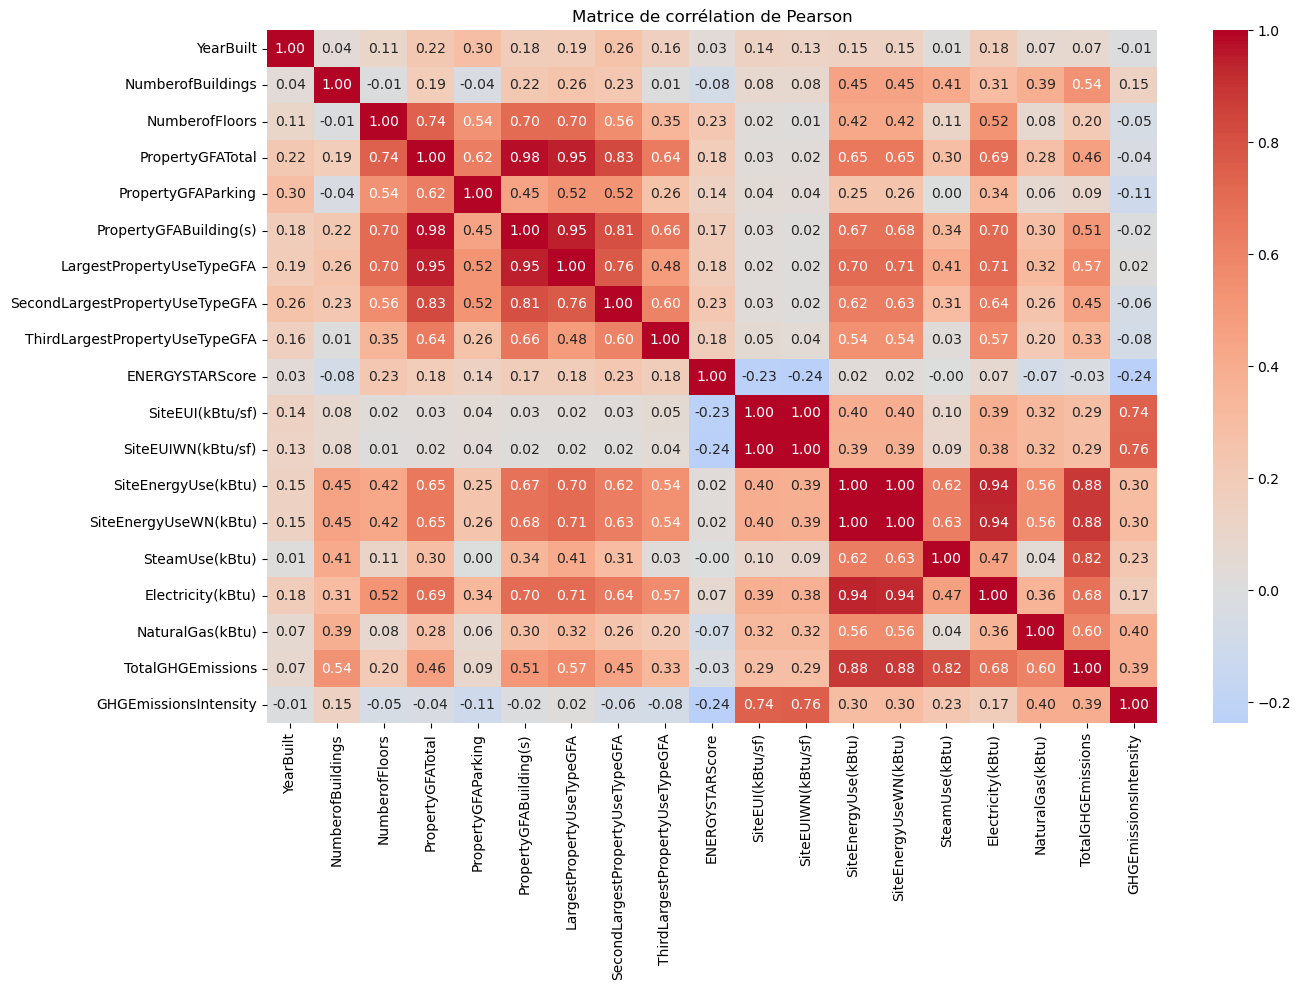

In [41]:
plt.figure(figsize=(14, 10))
sns.heatmap(df_model.select_dtypes(include='number').corr(), 
            annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matrice de corrélation de Pearson')
plt.tight_layout()
plt.show()

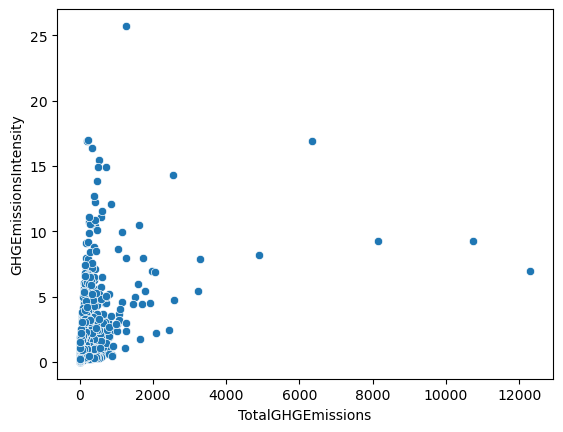

In [42]:
sns.scatterplot(
    data=df_model,
    x='TotalGHGEmissions',
    y='GHGEmissionsIntensity'
)

plt.show()

## >>> On ne droppe pas forcément les colonnes fortement corrélés entre elles pour permettre plus de souplesse ds le choix des features et targets par la suite 

# Fin EDA => df_model.to_parquet("data_clean.parquet")

In [44]:
df_model.shape

(1469, 25)

In [43]:
# export du dataset nettoyé

# df_model.to_csv("data_clean.csv", index=False)

df_model.to_parquet("data_clean.parquet")